<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FOil-Spill-Detection/notebooks/oil-spill/C4_02_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C4 – Step 3: Image processing + dark-patch detection
**Steps:** ① read image → ② reduce noise → ③ threshold → ④ clean up → ⑤ separate patches → labels (Oil / Look-alike)

Run the cells **from top to bottom, one by one** (▶️ or Shift+Enter).

## 1. Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Restore the dataset from the Drive backup
Extracts the backup saved in C4_01 (takes a few seconds).

In [ ]:
import os, pandas as pd
DRIVE_DIR = '/content/drive/MyDrive/C4_OilSpill'
DATA_DIR  = f'{DRIVE_DIR}/data'
RES_DIR   = f'{DRIVE_DIR}/results'
LOCAL_DIR = '/content/DARTIS'
IMG_DIR   = f'{LOCAL_DIR}/files'
os.makedirs(IMG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

if len(os.listdir(IMG_DIR)) == 0:
    !tar -xf "{DATA_DIR}/DARTIS_2019_files.tar" -C "{LOCAL_DIR}"
print('Files:', len(os.listdir(IMG_DIR)))

df = pd.read_csv(f'{DATA_DIR}/DARTIS_2019_metadata.csv')
df['exists'] = df['jpg_file'].apply(lambda n: os.path.exists(f'{IMG_DIR}/{n}'))
df = df[df.exists]
print('Rows:', len(df), '| Images:', df.jpg_file.nunique())

Files: 5020
Rows: 5515 | Images: 3655


## 3. Save the image-processing functions
These functions are saved to Drive as **`c4_utils.py`**. Later notebooks (features, training, frontend) **import** it instead of repeating the code.

| Function | Step |
|---|---|
| `load_gray` | ① Read image as grayscale (0–255) |
| `denoise` | ② Median filter (reduces speckle) |
| `dark_mask` | ③ Threshold: pixels **25%** darker than the surrounding sea (bright land excluded from the background) |
| `clean_mask` | ④ Morphology (remove small specks, join fragments) |
| `find_patches` | ⑤ Number the patches |
| `label_patches` | Inside an oil box = **oil**, no-oil image = **look-alike** |

In [ ]:
%%writefile /content/drive/MyDrive/C4_OilSpill/c4_utils.py
# c4_utils.py  –  C4 Oil Spill Detection: image processing helpers
# (Saved to Drive by the C4_02 notebook and imported by later notebooks.)
import numpy as np
import cv2
from skimage import measure
from scipy import ndimage as ndi

# ---- Settings (tunable) ----
MEDIAN_K   = 5      # speckle filter size (odd number)
BG_FRAC    = 0.5    # background window = 50% of the image's shorter side
DARK_RATIO = 0.75   # pixel < background * DARK_RATIO  ->  dark
LAND_FACTOR = 1.3   # pixels 30% brighter than sea level = land (excluded from background)
MIN_AREA   = 60     # remove patches smaller than this (pixels)
OPEN_K     = 3      # remove small noise specks
CLOSE_K    = 5      # join broken slick fragments


def load_gray(path):
    """① Read the image as grayscale (0-255)."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(path)
    return img


def denoise(img, k=None):
    """② Reduce speckle noise (median filter)."""
    return cv2.medianBlur(img, MEDIAN_K if k is None else k)


def dark_mask(filtered, bg_frac=None, ratio=None):
    """③ Threshold: pixels much darker than the surrounding sea (local background)."""
    bg_frac = BG_FRAC if bg_frac is None else bg_frac
    ratio = DARK_RATIO if ratio is None else ratio
    f = filtered.astype(np.float32)
    k = max(151, int(min(f.shape) * bg_frac) | 1)   # odd window, large enough for big look-alikes
    # Exclude bright land pixels from the background, so near-shore sea is not falsely "dark"
    valid = f > 0
    sea_level = np.median(f[valid]) if valid.any() else 1.0
    w = (valid & (f < LAND_FACTOR * sea_level)).astype(np.float32)
    background = cv2.blur(f * w, (k, k)) / np.maximum(cv2.blur(w, (k, k)), 1e-3)
    return (f < background * ratio) & valid      # valid: excludes image border / no-data


def clean_mask(mask, open_k=None, close_k=None, min_area=None):
    """④ Morphology: remove small specks, join fragments and fill holes."""
    open_k = OPEN_K if open_k is None else open_k
    close_k = CLOSE_K if close_k is None else close_k
    min_area = MIN_AREA if min_area is None else min_area
    m = mask.astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN,  np.ones((open_k, open_k), np.uint8))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((close_k, close_k), np.uint8))
    m = ndi.binary_fill_holes(m > 0)
    lab = measure.label(m > 0, connectivity=2)
    sizes = np.bincount(lab.ravel())
    keep = sizes >= min_area
    keep[0] = False
    return keep[lab]


def find_patches(clean):
    """⑤ Group connected pixels into numbered patches."""
    labels = measure.label(clean, connectivity=2)
    return labels, measure.regionprops(labels)


def detect(path):
    """Run steps ①-⑤ in one call."""
    img = load_gray(path)
    filt = denoise(img)
    raw = dark_mask(filt)
    clean = clean_mask(raw)
    labels, props = find_patches(clean)
    return dict(img=img, filtered=filt, raw=raw, clean=clean, labels=labels, props=props)


def label_patches(props, boxes, is_oil_image, min_overlap=0.5):
    """
    Assign a label to every patch:
      - No-oil image         -> 'look-alike'
      - Oil image, inside an oil box (>= min_overlap of the patch) -> 'oil'
      - Oil image, outside the boxes -> 'ignore' (uncertain, not used)
    boxes: [(xmin, ymin, xmax, ymax), ...] pixel coords
    """
    out = []
    for p in props:
        if not is_oil_image:
            out.append('look-alike')
            continue
        coords = p.coords  # (row, col)
        inside = np.zeros(len(coords), bool)
        for (x0, y0, x1, y1) in boxes:
            inside |= (coords[:, 1] >= x0) & (coords[:, 1] <= x1) & \
                      (coords[:, 0] >= y0) & (coords[:, 0] <= y1)
        out.append('oil' if inside.mean() >= min_overlap else 'ignore')
    return out


def boxes_detected(props, labels_list, boxes):
    """Which oil boxes were found by the threshold step (detection check)."""
    hit = [False] * len(boxes)
    for p, lab in zip(props, labels_list):
        if lab != 'oil':
            continue
        r0, c0, r1, c1 = p.bbox
        for i, (x0, y0, x1, y1) in enumerate(boxes):
            if c0 <= x1 and c1 >= x0 and r0 <= y1 and r1 >= y0:
                hit[i] = True
    return hit


Overwriting /content/drive/MyDrive/C4_OilSpill/c4_utils.py


In [ ]:
import sys, importlib
sys.path.insert(0, DRIVE_DIR)
import c4_utils as u
importlib.reload(u)
print('c4_utils ready ✅')

c4_utils ready ✅


## 4. Helper: get the oil boxes of an image

In [ ]:
def get_boxes(name):
    rows = df[(df.jpg_file == name) & df.is_oil]
    return list(zip(rows.obj_patchloc_xmin, rows.obj_patchloc_ymin,
                    rows.obj_patchloc_xmax, rows.obj_patchloc_ymax))

oil_names   = df[df.is_oil].jpg_file.unique()
nooil_names = df[~df.is_oil].jpg_file.unique()
print('Oil images:', len(oil_names), '| No-oil images:', len(nooil_names))

Oil images: 1365 | No-oil images: 2290


## 5. Show the 5 pipeline steps 👀
Top row: **oil image** · Bottom row: **look-alike image**
Last column: 🔴 red = oil · 🟡 yellow = look-alike · ⚪ grey = ignore (outside oil boxes) · cyan boxes = dataset oil boxes

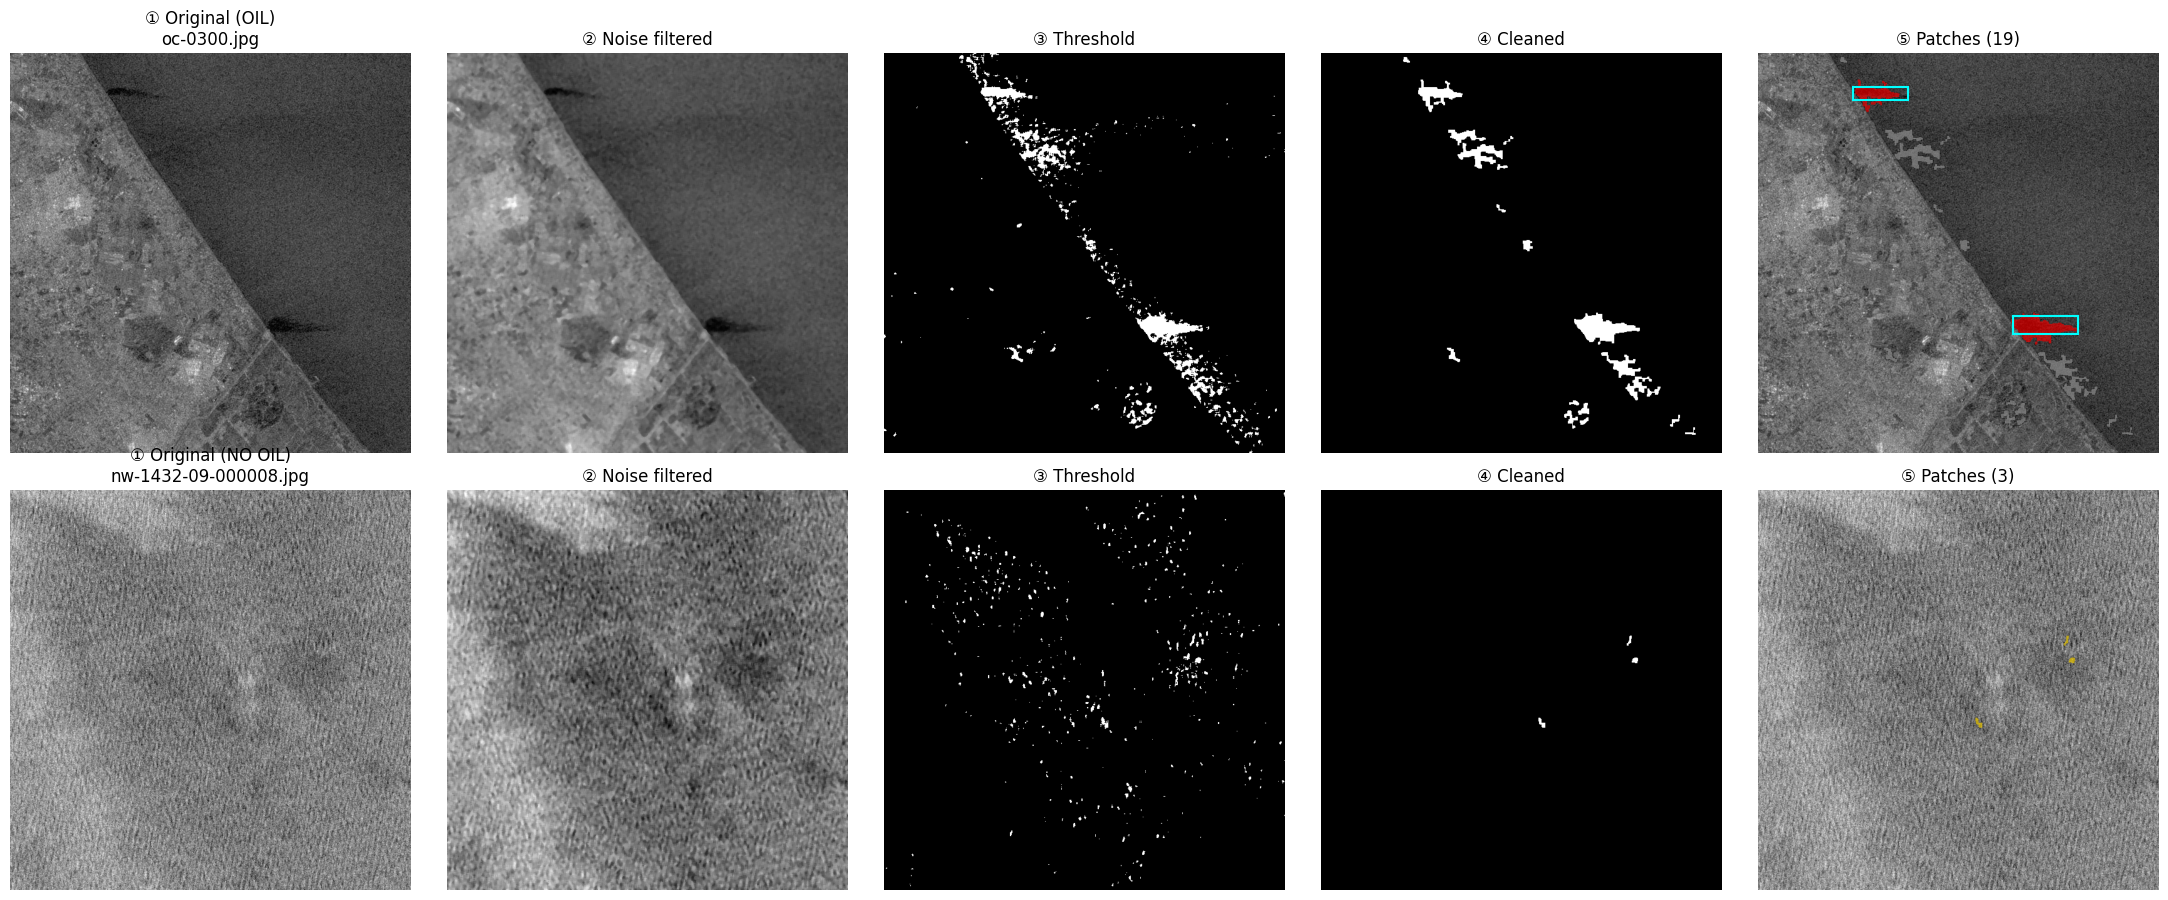

In [ ]:
import numpy as np, matplotlib.pyplot as plt, matplotlib.patches as mpatches

COLORS = {'oil': (1, 0, 0), 'look-alike': (1, 0.85, 0), 'ignore': (0.6, 0.6, 0.6)}

def overlay(res, labs):
    rgb = np.stack([res['img']]*3, -1).astype(float) / 255
    for p, lab in zip(res['props'], labs):
        rr, cc = p.coords[:, 0], p.coords[:, 1]
        rgb[rr, cc] = 0.35 * rgb[rr, cc] + 0.65 * np.array(COLORS[lab])
    return rgb

def show_pipeline(name, is_oil, axes_row):
    res = u.detect(f'{IMG_DIR}/{name}')
    boxes = get_boxes(name) if is_oil else []
    labs = u.label_patches(res['props'], boxes, is_oil)
    panels = [(res['img'], '① Original'), (res['filtered'], '② Noise filtered'),
              (res['raw'], '③ Threshold'), (res['clean'], '④ Cleaned'),
              (overlay(res, labs), f'⑤ Patches ({len(labs)})')]
    for ax, (im, title) in zip(axes_row, panels):
        ax.imshow(im, cmap='gray'); ax.set_title(title); ax.axis('off')
    for (x0, y0, x1, y1) in boxes:
        axes_row[-1].add_patch(mpatches.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, edgecolor='cyan', lw=1.5))
    axes_row[0].set_ylabel(name)
    return labs

rng = np.random.default_rng(7)
oil_example   = rng.choice(oil_names)
nooil_example = rng.choice(nooil_names)

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
show_pipeline(oil_example, True, axes[0])
show_pipeline(nooil_example, False, axes[1])
axes[0][0].set_title(f'① Original (OIL)\n{oil_example}')
axes[1][0].set_title(f'① Original (NO OIL)\n{nooil_example}')
plt.tight_layout()
plt.savefig(f'{RES_DIR}/02_pipeline.png', dpi=120)
plt.show()

💡 To view other images, change **7** in `default_rng(7)` in the cell above and run it again (e.g. 1, 2, 3…).

## 6. How well does the threshold work? (sample of 300 + 300)
- **Oil detection rate:** % of dataset oil boxes in which the threshold **found an oil patch**
- **Look-alike patches:** number of dark patches found in no-oil images

Takes about 1–3 minutes.

In [ ]:
from tqdm.auto import tqdm

N = 300
sample_oil   = rng.choice(oil_names,   min(N, len(oil_names)),   replace=False)
sample_nooil = rng.choice(nooil_names, min(N, len(nooil_names)), replace=False)

hits, counts = [], {'oil': 0, 'look-alike': 0, 'ignore': 0}
for name in tqdm(sample_oil, desc='Oil images'):
    res = u.detect(f'{IMG_DIR}/{name}'); boxes = get_boxes(name)
    labs = u.label_patches(res['props'], boxes, True)
    hits += u.boxes_detected(res['props'], labs, boxes)
    for l in labs: counts[l] += 1

for name in tqdm(sample_nooil, desc='No-oil images'):
    res = u.detect(f'{IMG_DIR}/{name}')
    counts['look-alike'] += len(res['props'])

print(f'\nOil boxes detected   : {sum(hits)}/{len(hits)} = {100*np.mean(hits):.1f}%')
print('Patches labels      :', counts)
print(f'Look-alike patches / no-oil image: {counts["look-alike"]/len(sample_nooil):.1f}')

Oil images:   0%|          | 0/300 [00:00<?, ?it/s]

No-oil images:   0%|          | 0/300 [00:00<?, ?it/s]


Oil boxes detected   : 593/739 = 80.2%
Patches labels      : {'oil': 1065, 'look-alike': 3849, 'ignore': 1166}
Look-alike patches / no-oil image: 12.8


### Interpreting the results + how to tune
| Result | Meaning | What to try |
|---|---|---|
| Oil detection rate **low** (e.g. < 70%) | Threshold too strict | `u.DARK_RATIO = 0.80` (increase) |
| **Many** look-alike patches (e.g. > 30 / image) | Sea noise is detected as patches | `u.DARK_RATIO = 0.70` or `u.MIN_AREA = 100` |

To change a setting, write that line in a new cell, run it, then **run Cells 5 and 6 again**.

**Note:** the threshold is a **simple rule**. It does not find every oil slick and it also finds false patches. That is expected: the next step's model (Random Forest / XGBoost) separates oil from look-alikes. This limitation is the reason for adding **U-Net** in PP2.

## ✅ Done!
`results/02_pipeline.png` is saved to Drive (for the PP1 image-processing slide).

**🔔 COMMIT:** File → Save a copy in GitHub → `notebooks/oil-spill/C4_02_preprocessing.ipynb` → `feat(oil-spill): add SAR image preprocessing and dark patch detection`